# 03-FedAvg, 10 clients IID

In [1]:
import sys
sys.path.append("..") 

import json
import torch
import matplotlib.pyplot as plt
from src.data import load_mnist, split_iid
from src.model import CNN
from src.client import local_train
from src.server import fedavg
from src.evaluate import evaluate

torch.manual_seed(0)
train, test = load_mnist()
clients = split_iid(train, n_clients=10)

In [2]:
global_model = CNN()
n_rounds = 20
accs = []

for r in range(n_rounds):
    updates = [local_train(global_model, c, epochs=1) for c in clients]
    global_model.load_state_dict(fedavg(updates))
    acc = evaluate(global_model, test)
    accs.append(acc)
    print(f"ronde {r + 1} : {acc:.4f}")

ronde 1 : 0.5746


ronde 2 : 0.7097


ronde 3 : 0.8294


ronde 4 : 0.8781


ronde 5 : 0.8959


...

ronde 16 : 0.9578


ronde 17 : 0.9587


ronde 18 : 0.9608


ronde 19 : 0.9641


ronde 20 : 0.9650


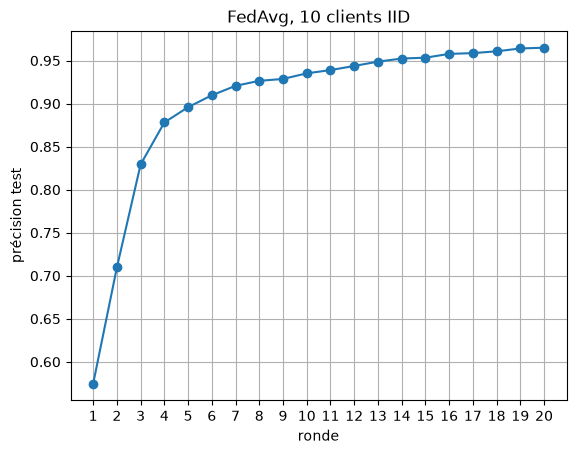

In [3]:
plt.plot(range(1, len(accs) + 1), accs, marker="o")
plt.xlabel("ronde")
plt.ylabel("précision test")
plt.title("FedAvg, 10 clients IID")
plt.grid(True)
plt.xticks(range(1, len(accs) + 1))
plt.savefig("../results/fedavg_iid.png")
plt.show()

In [4]:
with open("../results/fedavg_iid.json", "w") as f:
    json.dump(accs, f)